## Notebook 5: DINOv2


### 1. Imports and settings

In [ ]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import torch
import torchvision

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore")

# Paths
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()), None)
assert ROOT is not None, "Open this notebook from inside the 281project repo"
PROC = ROOT / "data" / "processed"
FEATURE_DIR = ROOT / "data" / "features"
RESULTS_DIR = ROOT / "data" / "results"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Network
HUB_REPO = "facebookresearch/dinov2"
MODEL_NAME = "dinov2_vitb14"          # vits14 / vitb14 / vitl14 / vitg14
MODEL_DIMS = {"dinov2_vits14": 384, "dinov2_vitb14": 768, "dinov2_vitl14": 1024, "dinov2_vitg14": 1536}
PATCH = 14                            # ViT patch size; input sides must be multiples of this
EMBED_WIDTH = 224                     # try 336 or 448 for finer detail (slower)
POOLING = "cls+mean"                  # "cls" or "cls+mean" (CLS token + average of patch tokens)
BATCH_SIZE = 32
RECOMPUTE_EMBEDDINGS = False
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# Keep model settings same as 4-resnet50
EMBED_DIM = MODEL_DIMS[MODEL_NAME] * (2 if POOLING == "cls+mean" else 1)
PCA_DIMS = [16, 32, 64, 128, 256, 512, EMBED_DIM]   # EMBED_DIM = no PCA
C_GRID = np.logspace(-6, 2, 13)
CLASS_WEIGHTS = [None, "balanced"]
MAX_ITER = 3000
SELECTION_RULE = "one_se"             # or "best"
N_VAL_BOOTSTRAP = 200

# RESnet50 refit here from cached embeddings
RESNET_PCA, RESNET_C, RESNET_WEIGHT = 64, 1e-4, None

# Baseline, test, timing settings
N_GUESS_SEEDS = 1000
N_BOOTSTRAP = 1000
N_TIMING_IMAGES = 50
TIMING_CPU_THREADS = 1
N_GALLERY = 5
OFFSET_GRID = np.round(np.arange(-3, 1.0001, 0.1), 2)
RESNET_MS_PER_IMAGE = 142.0           # 4-resnet50, CPU 1 thread
SIMPLE_MS_PER_IMAGE = 29.6            # 3-simple_model (combo)
SEED = 281
CLASS_NAMES = ["Small", "Medium", "Large"]
CLASS_COLORS = ["tab:green", "tab:orange", "tab:blue"]

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)

PyTorch 2.15.0 | torchvision 0.29.2 | device: mps


### 2. Load Data

In [2]:
manifest = pd.read_csv(PROC / "manifest.csv", keep_default_na=False)
splits, y = {}, {}
for split_name in ["train", "val", "test"]:
    splits[split_name] = manifest[manifest["split"] == split_name].reset_index(drop=True)
    y[split_name] = splits[split_name]["label"].to_numpy()
    c = np.bincount(y[split_name], minlength=3)
    print(split_name, "-> Small:", c[0], " Medium:", c[1], " Large:", c[2], " total:", c.sum())

for column in ["source_id", "group_id"]:
    ids = {s: set(splits[s][column]) for s in splits}
    overlap = len(ids["train"] & ids["val"]) + len(ids["train"] & ids["test"]) + len(ids["val"] & ids["test"])
    print(column, "shared between splits:", overlap)
    assert overlap == 0, "Leakage between splits - re-run 1-preprocessing.ipynb"

is_original = (splits["train"]["variant"] == "original").to_numpy()
y_train_maps = y["train"][is_original]

train -> Small: 590  Medium: 1240  Large: 1240  total: 3070
val -> Small: 26  Medium: 54  Large: 213  total: 293
test -> Small: 25  Medium: 53  Large: 213  total: 291
source_id shared between splits: 0
group_id shared between splits: 0


### 3. (recap) Baselines

In [3]:
def macro_mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    steps = np.abs(np.asarray(y_pred) - y_true)
    return float(np.mean([steps[y_true == c].mean() for c in [0, 1, 2] if np.any(y_true == c)]))

def steps_off_per_class(y_true, y_pred):
    return np.array([np.abs(y_pred[y_true == c] - c).mean() for c in [0, 1, 2]])

def get_scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
            "macro_mae": macro_mae(y_true, y_pred)}

def macro_f1_fast(y_true, y_pred):
    counts = np.bincount(3 * y_true + y_pred, minlength=9).reshape(3, 3)
    tp = np.diag(counts)
    fp, fn = counts.sum(axis=0) - tp, counts.sum(axis=1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(3), where=den > 0).mean()

no_features_train = np.zeros((len(y_train_maps), 1))
majority = DummyClassifier(strategy="most_frequent").fit(no_features_train, y_train_maps)

baseline_rows, majority_pred = [], {}
guess_f1, guess_per_class, guess_steps = {}, {}, {}
for split_name in ["val", "test"]:
    nf = np.zeros((len(y[split_name]), 1))
    majority_pred[split_name] = majority.predict(nf)
    baseline_rows.append({"model": "majority_class", "split": split_name,
                          **get_scores(y[split_name], majority_pred[split_name])})
    runs, per_class, steps = [], [], []
    for seed in range(N_GUESS_SEEDS):
        guess = DummyClassifier(strategy="stratified", random_state=seed).fit(no_features_train, y_train_maps).predict(nf)
        runs.append(get_scores(y[split_name], guess))
        per_class.append(f1_score(y[split_name], guess, labels=[0, 1, 2], average=None, zero_division=0))
        steps.append(steps_off_per_class(y[split_name], guess))
    runs = pd.DataFrame(runs)
    guess_f1[split_name] = runs["macro_f1"].to_numpy()
    guess_per_class[split_name] = np.mean(per_class, axis=0)
    guess_steps[split_name] = np.mean(steps, axis=0)
    baseline_rows.append({"model": "random_guess (mean)", "split": split_name, **runs.mean().to_dict(),
                          "macro_f1_low": np.percentile(guess_f1[split_name], 2.5),
                          "macro_f1_high": np.percentile(guess_f1[split_name], 97.5)})
baseline_table = pd.DataFrame(baseline_rows)

def baseline_value(model, split_name, column="macro_f1"):
    m = baseline_table[(baseline_table["model"] == model) & (baseline_table["split"] == split_name)]
    return m[column].item()

majority_val_f1, majority_test_f1 = baseline_value("majority_class", "val"), baseline_value("majority_class", "test")
chance_val_f1, chance_test_f1 = baseline_value("random_guess (mean)", "val"), baseline_value("random_guess (mean)", "test")
chance_test_range = (baseline_value("random_guess (mean)", "test", "macro_f1_low"),
                     baseline_value("random_guess (mean)", "test", "macro_f1_high"))
majority_test_mae = baseline_value("majority_class", "test", "macro_mae")
chance_test_mae = baseline_value("random_guess (mean)", "test", "macro_mae")
baseline_table.round(3)

,model,split,accuracy,balanced_acc,macro_f1,macro_mae,macro_f1_low,macro_f1_high
0,majority_class,val,0.727,0.333,0.281,1.00,NaN,NaN
1,random_guess (mean),val,0.571,0.333,0.332,0.94,0.277,0.391
2,majority_class,test,0.732,0.333,0.282,1.00,NaN,NaN
3,random_guess (mean),test,0.574,0.333,0.332,0.94,0.279,0.389


### 4. Dinov2 requirements
Cuts the image into 14x14 patches. Each patch is then a token. Model outputs CLS token (a summary of the whole image) and one patch token per patch (768 numbers each).

### 5. DINOv2 processing

In [4]:
with Image.open(PROC / splits["train"]["path"][0]) as img:
    processed_width, processed_height = img.size

def snap(v):
    return max(1, round(v / PATCH)) * PATCH

EMBED_SIZE = (snap(EMBED_WIDTH), snap(EMBED_WIDTH * processed_height / processed_width))   # (width, height)
GRID = (EMBED_SIZE[1] // PATCH, EMBED_SIZE[0] // PATCH)                                     # (rows, cols) of patches
print(f"Processed maps: {processed_width} x {processed_height} -> network input {EMBED_SIZE[0]} x {EMBED_SIZE[1]} "
      f"= {GRID[0]} x {GRID[1]} = {GRID[0] * GRID[1]} patches")

def prepare_image(path):
    """Processed map -> tensor (3, height, width): RGB, resized (whole page, no crop), ImageNet-normalized."""
    with Image.open(path) as img:
        small = img.convert("RGB").resize(EMBED_SIZE, Image.BICUBIC)   # bicubic is what DINOv2's own transforms use
    pixels = np.asarray(small, dtype=np.float32) / 255.0
    pixels = (pixels - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(pixels.transpose(2, 0, 1)))

def to_displayable(t):
    return np.clip(t.numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

Processed maps: 673 x 1024 -> network input 224 x 336 = 24 x 16 = 384 patches


### 6. DINOv2 steps
each patch token has 768 numbers. For each map, we run a 3-component PCA across that map's patch tokens and show components as RBG. Patches that are similar get similar colors. 

In [5]:
extractor = torch.hub.load(HUB_REPO, MODEL_NAME)
extractor.eval()
for p in extractor.parameters():
    p.requires_grad = False
extractor = extractor.to(DEVICE)
assert extractor.embed_dim == MODEL_DIMS[MODEL_NAME]
print(f"{MODEL_NAME}: {sum(p.numel() for p in extractor.parameters()) / 1e6:.1f} million weights, all frozen")

def embed_batch(batch):
    """(B, 3, H, W) -> (B, EMBED_DIM). CLS token, optionally followed by the mean of the patch tokens."""
    out = extractor.forward_features(batch)
    cls = out["x_norm_clstoken"]
    if POOLING == "cls":
        return cls
    return torch.cat([cls, out["x_norm_patchtokens"].mean(dim=1)], dim=1)

# One random train map per class (reused below)
rng = np.random.default_rng(SEED)
example_rows = {c: rng.choice(np.where(is_original & (y["train"] == c))[0]) for c in range(3)}

x = prepare_image(PROC / splits["train"].loc[example_rows[0], "path"]).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    feats = extractor.forward_features(x)
    emb = embed_batch(x)
assert torch.allclose(emb[:, :MODEL_DIMS[MODEL_NAME]], feats["x_norm_clstoken"])
print(pd.DataFrame([
    {"output": "input image", "shape": tuple(x.shape)},
    {"output": "patch tokens", "shape": tuple(feats["x_norm_patchtokens"].shape)},
    {"output": "CLS token", "shape": tuple(feats["x_norm_clstoken"].shape)},
    {"output": f"embedding ({POOLING})", "shape": tuple(emb.shape)},
]).to_string(index=False))

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /Users/hsinyehtsai/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /Users/hsinyehtsai/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:18<00:00, 19.1MB/s] 


dinov2_vitb14: 86.6 million weights, all frozen
              output            shape
         input image (1, 3, 336, 224)
        patch tokens    (1, 384, 768)
           CLS token         (1, 768)
embedding (cls+mean)        (1, 1536)


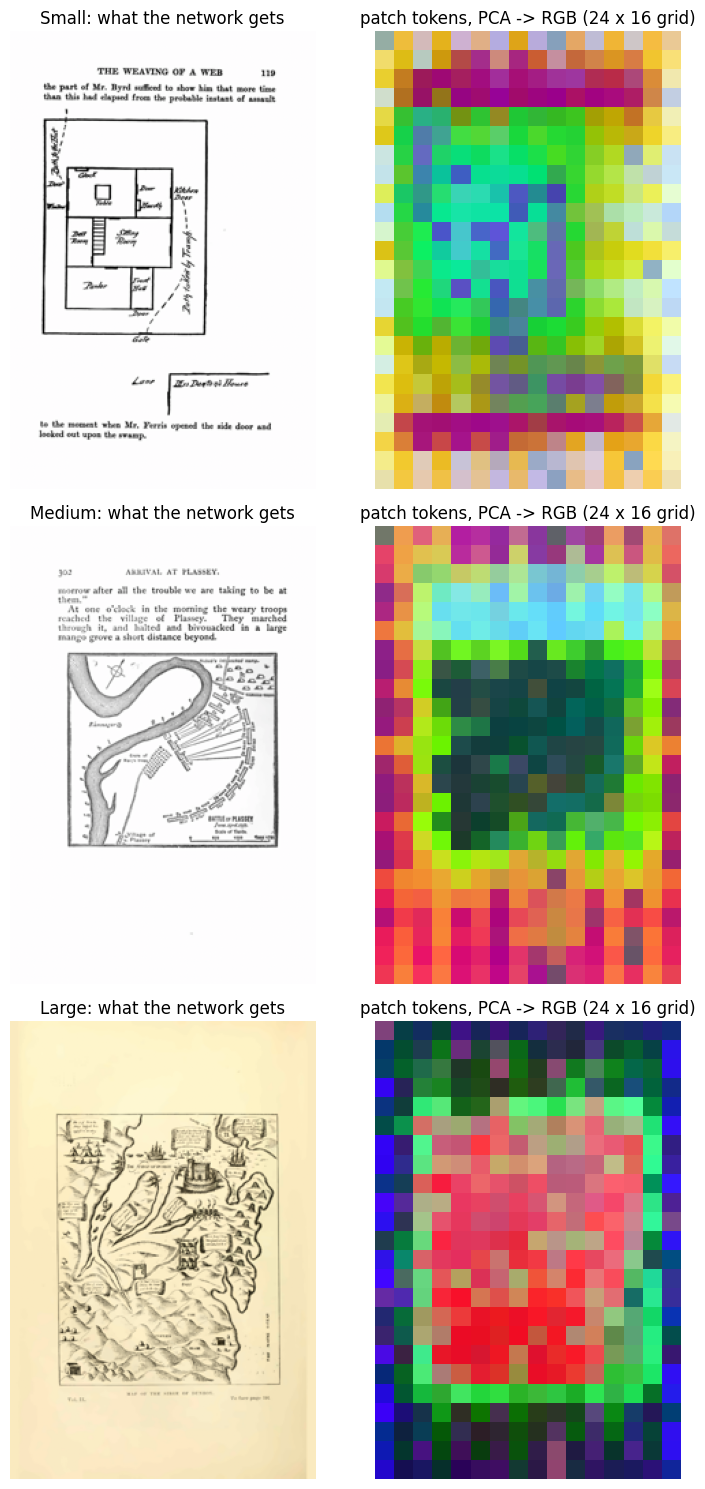

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(8, 15))
for c in range(3):
    t = prepare_image(PROC / splits["train"].loc[example_rows[c], "path"])
    with torch.no_grad():
        tokens = extractor.forward_features(t.unsqueeze(0).to(DEVICE))["x_norm_patchtokens"][0].cpu().numpy()
    rgb = PCA(n_components=3, random_state=SEED).fit_transform(tokens)
    rgb = (rgb - rgb.min(0)) / (rgb.max(0) - rgb.min(0) + 1e-9)
    axes[c, 0].imshow(to_displayable(t)); axes[c, 0].set_title(f"{CLASS_NAMES[c]}: what the network gets")
    axes[c, 1].imshow(rgb.reshape(GRID[0], GRID[1], 3), interpolation="nearest")
    axes[c, 1].set_title(f"patch tokens, PCA -> RGB ({GRID[0]} x {GRID[1]} grid)")
    for ax in axes[c]:
        ax.axis("off")
plt.tight_layout(); plt.show()

### 7. run embeddings for each image
takes a few minutes! 
checks manifest rows

In [11]:
CACHE_INFO = {"model": MODEL_NAME, "embed_size": list(EMBED_SIZE), "pooling": POOLING, "resize": "bicubic"}

def embed_paths(paths, desc):
    chunks, t0 = [], time.perf_counter()
    for start in range(0, len(paths), BATCH_SIZE):
        batch = torch.stack([prepare_image(PROC / p) for p in paths[start:start + BATCH_SIZE]]).to(DEVICE)
        with torch.no_grad():
            chunks.append(embed_batch(batch).cpu().numpy())
        print(f"\r{desc}: {min(start + BATCH_SIZE, len(paths))}/{len(paths)} images ({time.perf_counter() - t0:.0f} s)", end="")
    print()
    return np.concatenate(chunks).astype(np.float32), time.perf_counter() - t0

def cache_file(split_name):
    return FEATURE_DIR / f"{MODEL_NAME}_{split_name}.npz"

def load_saved(split_name, paths):
    f = cache_file(split_name)
    if RECOMPUTE_EMBEDDINGS or not f.exists():
        return None
    saved = np.load(f, allow_pickle=False)
    if saved["paths"].tolist() == list(paths) and json.loads(str(saved["info"])) == CACHE_INFO:
        return saved["X"], float(saved["seconds"]), str(saved["device"])
    print(f"{f.name} is out of date - recomputing")
    return None

X, extract_seconds, extract_device = {}, {}, {}
for split_name in ["train", "val", "test"]:
    paths = splits[split_name]["path"].tolist()
    saved = load_saved(split_name, paths)
    if saved is not None:
        X[split_name], extract_seconds[split_name], extract_device[split_name] = saved
        print(f"{split_name}: loaded {len(paths)} saved embeddings")
    else:
        X[split_name], extract_seconds[split_name] = embed_paths(paths, split_name)
        extract_device[split_name] = DEVICE
        np.savez(cache_file(split_name), X=X[split_name], paths=np.array(paths), info=json.dumps(CACHE_INFO),
                 seconds=extract_seconds[split_name], device=DEVICE)
    print(f"   {split_name}: {X[split_name].shape}")
assert X["train"].shape[1] == EMBED_DIM

train: 3070/3070 images (274 s)
   train: (3070, 1536)
val: 293/293 images (25 s)
   val: (293, 1536)
test: 291/291 images (27 s)
   test: (291, 1536)


##### load resnet for comparison

In [12]:
def load_resnet_embeddings():
    out = {}
    for s in splits:
        f = FEATURE_DIR / f"resnet50_{s}.npz"
        if not f.exists():
            print(f"{f.name} not found - run 4-resnet50.ipynb; ResNet comparisons will be skipped")
            return None
        saved = np.load(f, allow_pickle=False)
        if saved["paths"].tolist() != splits[s]["path"].tolist():
            print(f"{f.name} doesn't match the current manifest - re-run 4-resnet50.ipynb")
            return None
        out[s] = saved["X"]
    return out

X_res = load_resnet_embeddings()

##### timing comparison

In [13]:
timing_paths = splits["train"]["path"].tolist()[:N_TIMING_IMAGES]
threads_before = torch.get_num_threads()
extractor.to("cpu"); torch.set_num_threads(TIMING_CPU_THREADS)
try:
    prep_s = net_s = 0.0
    with torch.no_grad():
        embed_batch(prepare_image(PROC / timing_paths[0]).unsqueeze(0))   # warm-up
        for p in timing_paths:
            t = time.perf_counter(); one = prepare_image(PROC / p).unsqueeze(0); prep_s += time.perf_counter() - t
            t = time.perf_counter(); embed_batch(one); net_s += time.perf_counter() - t
finally:
    torch.set_num_threads(threads_before); extractor.to(DEVICE)
prep_ms, network_ms = 1000 * prep_s / len(timing_paths), 1000 * net_s / len(timing_paths)
embed_ms_per_image = prep_ms + network_ms
print(f"CPU, 1 thread: {embed_ms_per_image:.1f} ms per image (load+prepare {prep_ms:.1f}, network {network_ms:.1f})")

CPU, 1 thread: 203.3 ms per image (load+prepare 15.3, network 188.0)


### 8. Check Embeddings

##### 8a. Which embedding numbers differ most between classes?

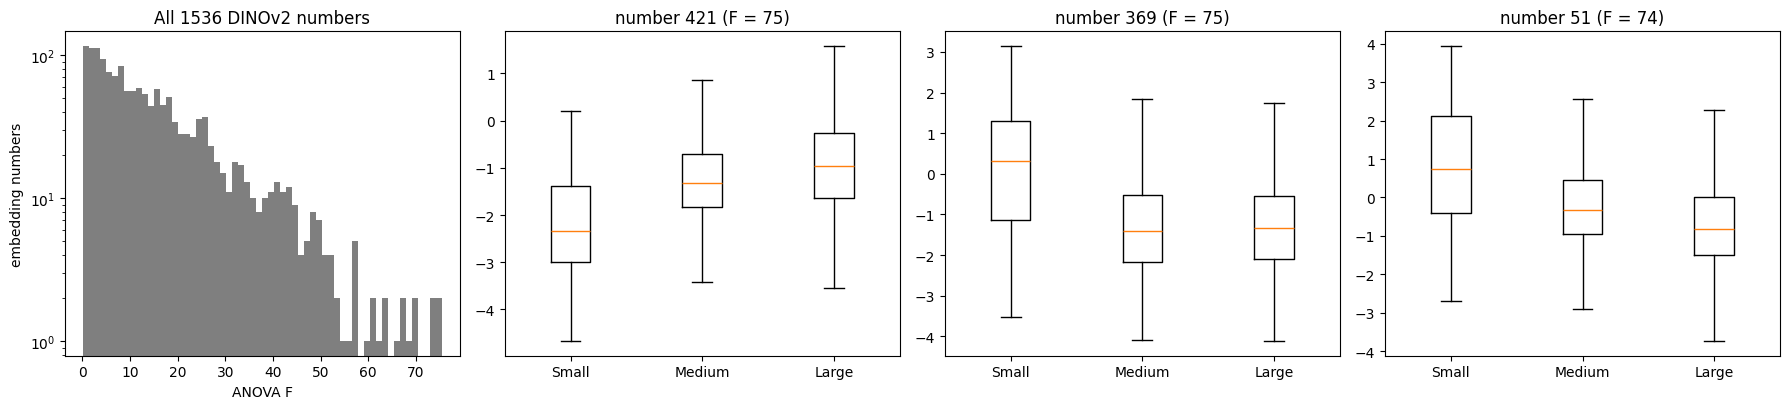

984 of 1536 numbers (64.1%) differ at p < 0.001 (chance: ~2)
799 pass Bonferroni (p < 3.3e-05)
ResNet-50 on the 11/4 run: 279 of 2048 (13.6%), 151 Bonferroni, top F = 64


In [14]:
X_train_maps = X["train"][is_original]
F, p_values = f_classif(X_train_maps, y_train_maps)
F = np.nan_to_num(F)
top_dims = np.argsort(F)[::-1][:3]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].hist(F, bins=60, color="tab:gray"); axes[0].set_yscale("log")
axes[0].set_xlabel("ANOVA F"); axes[0].set_ylabel("embedding numbers"); axes[0].set_title(f"All {EMBED_DIM} DINOv2 numbers")
for ax, dim in zip(axes[1:], top_dims):
    ax.boxplot([X_train_maps[y_train_maps == c, dim] for c in range(3)], showfliers=False)
    ax.set_xticks([1, 2, 3], CLASS_NAMES); ax.set_title(f"number {dim} (F = {F[dim]:.0f})")
plt.tight_layout(); plt.show()

n_sig = (p_values < 0.001).sum()
print(f"{n_sig} of {EMBED_DIM} numbers ({n_sig / EMBED_DIM:.1%}) differ at p < 0.001 (chance: ~{0.001 * EMBED_DIM:.0f})")
print(f"{(p_values < 0.05 / EMBED_DIM).sum()} pass Bonferroni (p < {0.05 / EMBED_DIM:.1e})")
print("ResNet-50 on the 11/4 run: 279 of 2048 (13.6%), 151 Bonferroni, top F = 64")

##### 8b. PCA of resnet and dino

ResNet-50: 50% of variance in 61 components, 80% in 271, first two = 10.7%
DINOv2: 50% of variance in 11 components, 80% in 76, first two = 22.1%


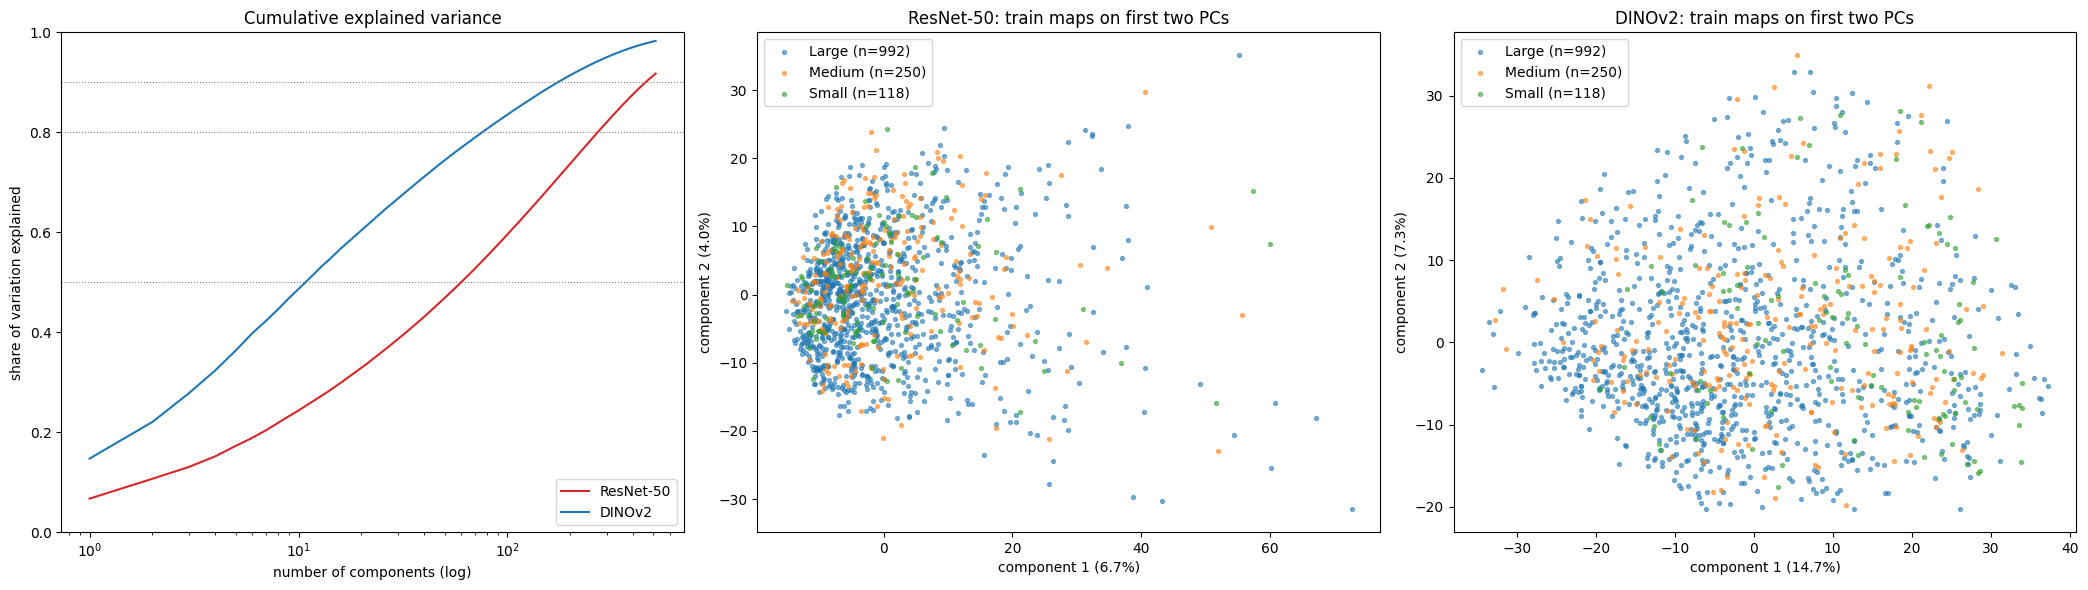

In [15]:
def fit_viz_pca(Xtr_maps):
    sc = StandardScaler().fit(Xtr_maps)
    pca = PCA(n_components=min(512, len(Xtr_maps) - 1), random_state=SEED).fit(sc.transform(Xtr_maps))
    return sc, pca

models_emb = {"DINOv2": X}
if X_res is not None:
    models_emb = {"ResNet-50": X_res, "DINOv2": X}
viz = {}
for name, Xm in models_emb.items():
    sc, pca = fit_viz_pca(Xm["train"][is_original])
    viz[name] = {"sc": sc, "pca": pca, "Z": pca.transform(sc.transform(Xm["train"][is_original]))}

fig, axes = plt.subplots(1, 1 + len(viz), figsize=(7 * (1 + len(viz)), 6))
line_colors = {"ResNet-50": "tab:red", "DINOv2": "tab:blue"}
for name, v in viz.items():
    cum = np.cumsum(v["pca"].explained_variance_ratio_)
    axes[0].plot(np.arange(1, len(cum) + 1), cum, color=line_colors[name], label=name)
    print(f"{name}: 50% of variance in {np.searchsorted(cum, 0.5) + 1} components, "
          f"80% in {np.searchsorted(cum, 0.8) + 1}, first two = {cum[1]:.1%}")
for level in [0.5, 0.8, 0.9]:
    axes[0].axhline(level, color="gray", linestyle=":", linewidth=0.8)
axes[0].set_xscale("log"); axes[0].set_ylim(0, 1)
axes[0].set_xlabel("number of components (log)"); axes[0].set_ylabel("share of variation explained")
axes[0].set_title("Cumulative explained variance"); axes[0].legend()
for ax, (name, v) in zip(axes[1:], viz.items()):
    for c in [2, 1, 0]:
        rows = y_train_maps == c
        ax.scatter(v["Z"][rows, 0], v["Z"][rows, 1], s=8, alpha=0.55, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (n={rows.sum()})")
    ax.set_xlabel(f"component 1 ({v['pca'].explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"component 2 ({v['pca'].explained_variance_ratio_[1]:.1%})")
    ax.set_title(f"{name}: train maps on first two PCs"); ax.legend()
plt.tight_layout(); plt.show()

##### 8c. tSNE and neighbor check


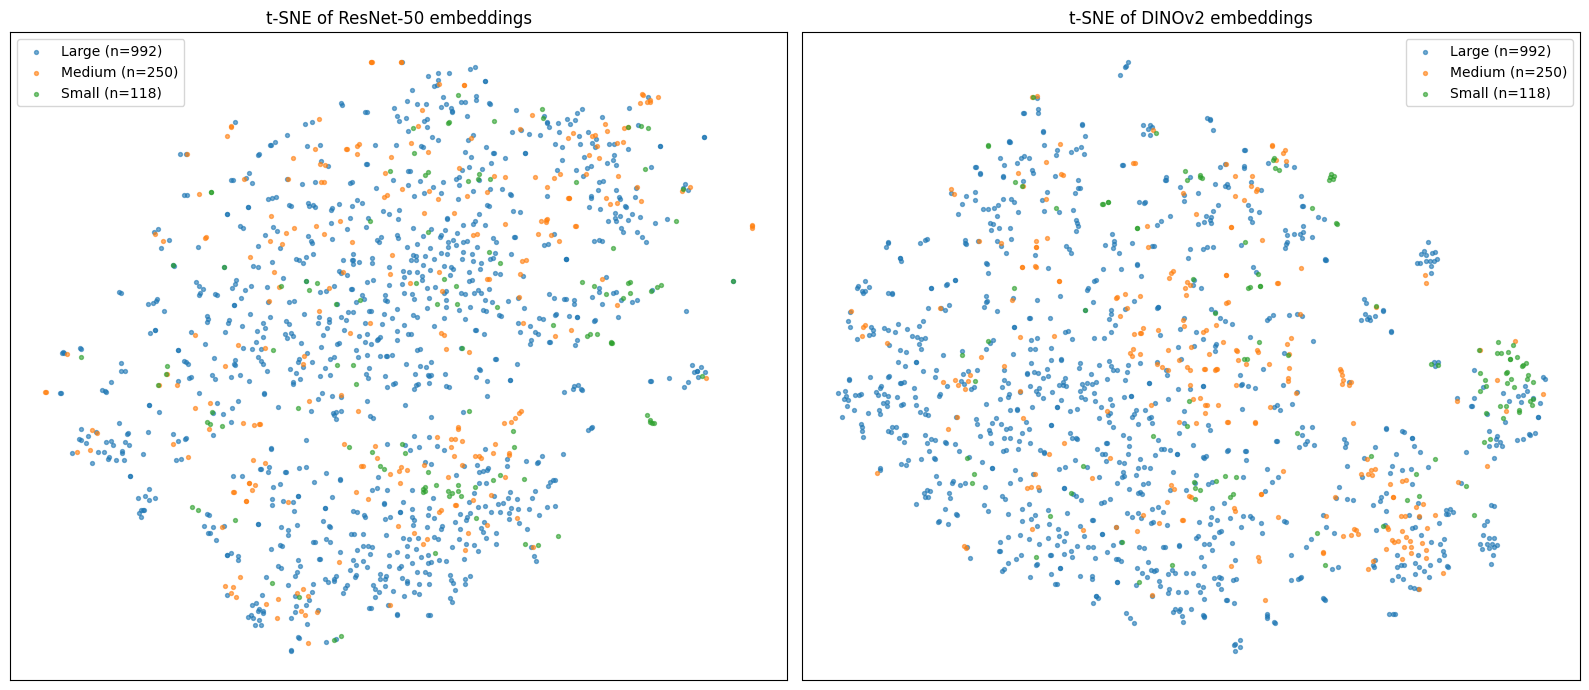

,ResNet-50: same-class share of 10 nearest neighbors,DINOv2: same-class share of 10 nearest neighbors,if neighbors were random
Small,0.250,0.344,0.087
Medium,0.329,0.390,0.184
Large,0.790,0.800,0.729


In [16]:
nn_rows = {}
fig, axes = plt.subplots(1, len(viz), figsize=(8 * len(viz), 7))
axes = np.atleast_1d(axes)
for ax, (name, v) in zip(axes, viz.items()):
    Z50 = v["Z"][:, :50]
    T2 = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z50)
    for c in [2, 1, 0]:
        rows = y_train_maps == c
        ax.scatter(T2[rows, 0], T2[rows, 1], s=8, alpha=0.6, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (n={rows.sum()})")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"t-SNE of {name} embeddings"); ax.legend()
    nbrs = NearestNeighbors(n_neighbors=11).fit(Z50).kneighbors(Z50, return_distance=False)[:, 1:]
    same = (y_train_maps[nbrs] == y_train_maps[:, None]).mean(axis=1)
    nn_rows[f"{name}: same-class share of 10 nearest neighbors"] = [same[y_train_maps == c].mean() for c in range(3)]
nn_rows["if neighbors were random"] = [np.mean(y_train_maps == c) for c in range(3)]
plt.tight_layout(); plt.show()
display(pd.DataFrame(nn_rows, index=CLASS_NAMES).round(3))

##### 8d. tune validation set

In [17]:
n_val = len(y["val"])
val_resamples = np.random.default_rng(SEED).integers(0, n_val, size=(N_VAL_BOOTSTRAP, n_val))

search_rows, t_start = [], time.perf_counter()
scaler = StandardScaler().fit(X["train"])
train_scaled, val_scaled = scaler.transform(X["train"]), scaler.transform(X["val"])

for n_dims in PCA_DIMS:
    t = time.perf_counter()
    if n_dims < EMBED_DIM:
        pca = PCA(n_components=n_dims, random_state=SEED).fit(train_scaled)
        train_in, val_in = pca.transform(train_scaled), pca.transform(val_scaled)
    else:
        train_in, val_in = train_scaled, val_scaled
    pca_seconds = time.perf_counter() - t
    for class_weight in CLASS_WEIGHTS:
        weighting = "balanced" if class_weight == "balanced" else "none"
        for C in C_GRID:
            logreg = LogisticRegression(C=C, class_weight=class_weight, max_iter=MAX_ITER, random_state=SEED)
            t = time.perf_counter()
            logreg.fit(train_in, y["train"])
            fit_s = time.perf_counter() - t + pca_seconds
            val_pred = logreg.predict(val_in)
            search_rows.append({
                "pca_dims": n_dims, "weighting": weighting, "C": C,
                "train_macro_f1": macro_f1_fast(y["train"], logreg.predict(train_in)),
                "val_macro_f1": macro_f1_fast(y["val"], val_pred),
                "val_f1_se": np.std([macro_f1_fast(y["val"][r], val_pred[r]) for r in val_resamples]),
                "converged": bool(np.max(logreg.n_iter_) < MAX_ITER), "fit_seconds": fit_s})
        best_here = max(r["val_macro_f1"] for r in search_rows if r["pca_dims"] == n_dims and r["weighting"] == weighting)
        print(f"PCA {n_dims:>4} | {weighting:<8} | best val macro-F1 = {best_here:.3f}  ({time.perf_counter() - t_start:.0f} s)")
search = pd.DataFrame(search_rows)
print(f"\n{(~search['converged']).sum()} of {len(search)} fits stopped at MAX_ITER before converging")

PCA   16 | none     | best val macro-F1 = 0.543  (0 s)
PCA   16 | balanced | best val macro-F1 = 0.528  (0 s)
PCA   32 | none     | best val macro-F1 = 0.559  (1 s)
PCA   32 | balanced | best val macro-F1 = 0.543  (1 s)
PCA   64 | none     | best val macro-F1 = 0.564  (1 s)
PCA   64 | balanced | best val macro-F1 = 0.545  (2 s)
PCA  128 | none     | best val macro-F1 = 0.574  (2 s)
PCA  128 | balanced | best val macro-F1 = 0.569  (2 s)
PCA  256 | none     | best val macro-F1 = 0.591  (3 s)
PCA  256 | balanced | best val macro-F1 = 0.577  (4 s)
PCA  512 | none     | best val macro-F1 = 0.575  (6 s)
PCA  512 | balanced | best val macro-F1 = 0.587  (8 s)
PCA 1536 | none     | best val macro-F1 = 0.571  (10 s)
PCA 1536 | balanced | best val macro-F1 = 0.581  (13 s)

0 of 182 fits stopped at MAX_ITER before converging


In [18]:
best = search.loc[search["val_macro_f1"].idxmax()]
threshold = best["val_macro_f1"] - best["val_f1_se"]
tied = search[search["val_macro_f1"] >= threshold]
simplest = tied.sort_values(["pca_dims", "C", "val_macro_f1"], ascending=[True, True, False]).iloc[0]
chosen = simplest if SELECTION_RULE == "one_se" else best

def pca_label(n):
    return "no PCA" if n >= EMBED_DIM else f"PCA {int(n)}"

def describe(r):
    return (f"{pca_label(r['pca_dims'])}, weighting {r['weighting']}, C = {r['C']:.1e}: val macro-F1 "
            f"{r['val_macro_f1']:.3f} (SE {r['val_f1_se']:.3f}), train {r['train_macro_f1']:.3f}")

print("Highest val score:", describe(best))
print(f"Within one SE (>= {threshold:.3f}): {len(tied)} of {len(search)} settings")
print("Simplest of those:", describe(simplest))
print(f"\nChosen ({SELECTION_RULE}):", describe(chosen))
print(f"Random guessing on val: {chance_val_f1:.3f}   Majority class on val: {majority_val_f1:.3f}")
(search.sort_values("val_macro_f1", ascending=False).head(10)
       .assign(C=lambda d: d["C"].map("{:.1e}".format)).round(3).reset_index(drop=True))

Highest val score: PCA 256, weighting none, C = 4.6e-04: val macro-F1 0.591 (SE 0.037), train 0.773
Within one SE (>= 0.554): 26 of 182 settings
Simplest of those: PCA 32, weighting none, C = 2.2e-05: val macro-F1 0.557 (SE 0.036), train 0.629

Chosen (one_se): PCA 32, weighting none, C = 2.2e-05: val macro-F1 0.557 (SE 0.036), train 0.629
Random guessing on val: 0.332   Majority class on val: 0.281


,pca_dims,weighting,C,train_macro_f1,val_macro_f1,val_f1_se,converged,fit_seconds
0,256,none,4.6e-04,0.773,0.591,0.037,True,0.142
1,512,balanced,4.6e-04,0.797,0.587,0.035,True,0.283
2,256,none,2.2e-03,0.821,0.587,0.039,True,0.151
3,1536,balanced,4.6e-04,0.802,0.581,0.035,True,0.133
4,256,balanced,4.6e-04,0.783,0.577,0.035,True,0.144
5,512,none,2.2e-03,0.868,0.575,0.041,True,0.306
6,128,none,1.0e-04,0.695,0.574,0.035,True,0.103
7,512,none,4.6e-04,0.786,0.571,0.038,True,0.290
8,1536,none,4.6e-04,0.789,0.571,0.038,True,0.133
9,128,balanced,4.6e-04,0.755,0.569,0.034,True,0.110


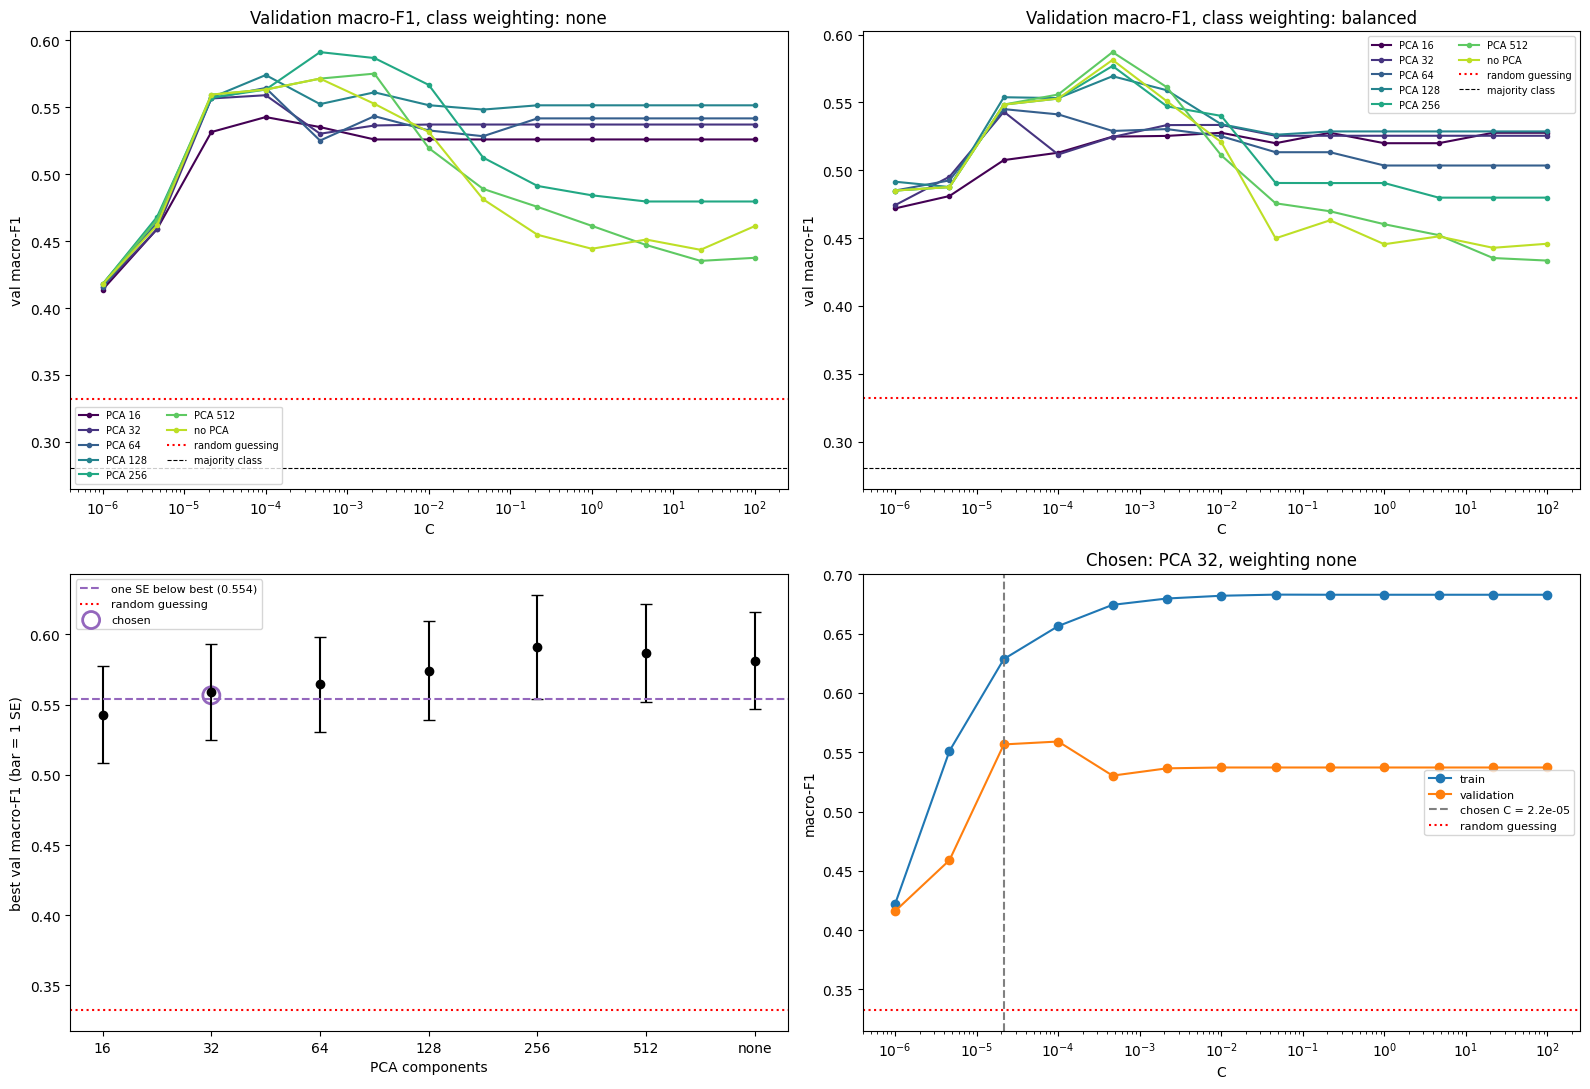

In [19]:
fig = plt.figure(figsize=(16, 11))
size_colors = plt.cm.viridis(np.linspace(0, 0.9, len(PCA_DIMS)))
for panel, weighting in enumerate(["none", "balanced"]):
    ax = fig.add_subplot(2, 2, panel + 1)
    for n_dims, color in zip(PCA_DIMS, size_colors):
        cur = search[(search["pca_dims"] == n_dims) & (search["weighting"] == weighting)]
        ax.plot(cur["C"], cur["val_macro_f1"], marker="o", markersize=3, color=color,
                label="no PCA" if n_dims == EMBED_DIM else f"PCA {n_dims}")
    ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
    ax.axhline(majority_val_f1, color="black", linestyle="--", linewidth=0.8, label="majority class")
    ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("val macro-F1")
    ax.set_title(f"Validation macro-F1, class weighting: {weighting}"); ax.legend(fontsize=7, ncol=2)

ax = fig.add_subplot(2, 2, 3)
bps = search.loc[search.groupby("pca_dims")["val_macro_f1"].idxmax()]
ax.errorbar(range(len(bps)), bps["val_macro_f1"], yerr=bps["val_f1_se"], fmt="o", capsize=4, color="black")
ax.axhline(threshold, color="tab:purple", linestyle="--", label=f"one SE below best ({threshold:.3f})")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
pos = list(bps["pca_dims"]).index(chosen["pca_dims"])
ax.scatter([pos], [chosen["val_macro_f1"]], s=150, facecolors="none", edgecolors="tab:purple", linewidths=2, label="chosen")
ax.set_xticks(range(len(bps)), ["none" if d == EMBED_DIM else str(d) for d in bps["pca_dims"]])
ax.set_xlabel("PCA components"); ax.set_ylabel("best val macro-F1 (bar = 1 SE)"); ax.legend(fontsize=8)

ax = fig.add_subplot(2, 2, 4)
cur = search[(search["pca_dims"] == chosen["pca_dims"]) & (search["weighting"] == chosen["weighting"])]
ax.plot(cur["C"], cur["train_macro_f1"], marker="o", label="train")
ax.plot(cur["C"], cur["val_macro_f1"], marker="o", label="validation")
ax.axvline(chosen["C"], color="gray", linestyle="--", label=f"chosen C = {chosen['C']:.1e}")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("macro-F1")
ax.set_title(f"Chosen: {pca_label(chosen['pca_dims'])}, weighting {chosen['weighting']}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
model_name = f"DINOv3 {MODEL_NAME.split('_')[1]} + logistic regression ({pca_label(FINAL_DIMS)})"
score_line = f"macro-F1 = {test_scores['macro_f1']:.3f}, macro MAE = {test_scores['macro_mae']:.3f}"
ConfusionMatrixDisplay(confusion_matrix(y["test"], test_pred, labels=[0, 1, 2]), display_labels=CLASS_NAMES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{model_name}\nTest confusion matrix (counts)\n{score_line}", fontsize=10)
ConfusionMatrixDisplay(confusion_matrix(y["test"], test_pred, labels=[0, 1, 2], normalize="true"), display_labels=CLASS_NAMES).plot(
    ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title(f"{model_name}\nRow-normalized (diagonal = recall)\n{score_line}", fontsize=10)
class_counts = np.bincount(y["test"], minlength=3)
bars = axes[2].bar(CLASS_NAMES, per_class_f1, color=CLASS_COLORS)
for k, b in enumerate(bars):
    axes[2].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"n={class_counts[k]}", ha="center")
axes[2].set_ylim(0, 1.1); axes[2].set_ylabel("F1"); axes[2].set_title(f"{model_name}\nTest F1 per class\n{score_line}", fontsize=10)
plt.tight_layout(); plt.show()

### 10. Final model and test run

In [20]:
FINAL_DIMS, FINAL_WEIGHTING, FINAL_C = int(chosen["pca_dims"]), chosen["weighting"], float(chosen["C"])
final_class_weight = "balanced" if FINAL_WEIGHTING == "balanced" else None

final_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=FINAL_DIMS, random_state=SEED) if FINAL_DIMS < EMBED_DIM else "passthrough"),
    ("logreg", LogisticRegression(C=FINAL_C, class_weight=final_class_weight, max_iter=MAX_ITER, random_state=SEED)),
])
t = time.perf_counter(); final_model.fit(X["train"], y["train"]); fit_seconds = time.perf_counter() - t
t = time.perf_counter(); test_pred = final_model.predict(X["test"]); predict_seconds = time.perf_counter() - t
val_pred = final_model.predict(X["val"])

val_scores, test_scores = get_scores(y["val"], val_pred), get_scores(y["test"], test_pred)
per_class_f1 = f1_score(y["test"], test_pred, labels=[0, 1, 2], average=None, zero_division=0)
n_test = len(y["test"])
two_step_errors = int((np.abs(test_pred - y["test"]) == 2).sum())
n_errors = int((test_pred != y["test"]).sum())

print(f"Chosen: {pca_label(FINAL_DIMS)}, class weighting {FINAL_WEIGHTING}, C = {FINAL_C:.2e} ({SELECTION_RULE})")
print(f"Val macro-F1:  {val_scores['macro_f1']:.3f}   val macro MAE: {val_scores['macro_mae']:.3f}")
print(f"Test macro-F1: {test_scores['macro_f1']:.3f}   (random guessing {chance_test_f1:.3f}, majority {majority_test_f1:.3f})")
print(f"Test macro MAE: {test_scores['macro_mae']:.3f} (random {chance_test_mae:.3f}, majority {majority_test_mae:.3f}; lower is better)")
print(f"Test balanced acc: {test_scores['balanced_acc']:.3f}   accuracy: {test_scores['accuracy']:.3f}")
print(f"Two-step errors: {two_step_errors} of {n_errors}")
print(f"Predicted per class: {np.bincount(test_pred, minlength=3)}   actual: {np.bincount(y['test'], minlength=3)}\n")
print(classification_report(y["test"], test_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=3))

Chosen: PCA 32, class weighting none, C = 2.15e-05 (one_se)
Val macro-F1:  0.557   val macro MAE: 0.568
Test macro-F1: 0.579   (random guessing 0.332, majority 0.282)
Test macro MAE: 0.486 (random 0.940, majority 1.000; lower is better)
Test balanced acc: 0.612   accuracy: 0.680
Two-step errors: 17 of 93
Predicted per class: [ 25  91 175]   actual: [ 25  53 213]

              precision    recall  f1-score   support

       Small      0.480     0.480     0.480        25
      Medium      0.374     0.642     0.472        53
       Large      0.869     0.714     0.784       213

    accuracy                          0.680       291
   macro avg      0.574     0.612     0.579       291
weighted avg      0.745     0.680     0.701       291



### 11. Compare: baseline, simple, resnet, dino2
bootstrap to get ci, then paired bootstrap.

In [21]:
def bootstrap_ci(pred):
    rng = np.random.default_rng(SEED)
    f1s, maes = [], []
    for _ in range(N_BOOTSTRAP):
        r = rng.integers(0, n_test, n_test)
        f1s.append(macro_f1_fast(y["test"][r], pred[r])); maes.append(macro_mae(y["test"][r], pred[r]))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(maes, [2.5, 97.5])

# --- ResNet-50 refit (deterministic, from cached embeddings) ---
resnet_model, resnet_pred = None, None
if X_res is not None:
    resnet_model = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=RESNET_PCA, random_state=SEED)),
        ("logreg", LogisticRegression(C=RESNET_C, class_weight=RESNET_WEIGHT, max_iter=MAX_ITER, random_state=SEED)),
    ]).fit(X_res["train"], y["train"])
    resnet_pred = resnet_model.predict(X_res["test"])
    print(f"ResNet-50 refit: test macro-F1 {macro_f1_fast(y['test'], resnet_pred):.3f} (notebook 4 reported 0.481)")

# --- 3-simple_model predictions, if saved ---
simple_pred = None
f = RESULTS_DIR / "3-simple_model_test_predictions.csv"
if f.exists():
    s = pd.read_csv(f)
    m = splits["test"]["path"].map(dict(zip(s["path"], s["pred"])))
    lab = splits["test"]["path"].map(dict(zip(s["path"], s["label"])))
    if not m.isna().any() and (lab.to_numpy() == y["test"]).all():
        simple_pred = m.to_numpy().astype(int)
    else:
        print("3-simple_model predictions don't match this test set - re-run 3-simple_model")
else:
    print("3-simple_model_test_predictions.csv not found - simple-feature comparison skipped")

preds = {"DINOv2": test_pred}
if resnet_pred is not None: preds["ResNet-50"] = resnet_pred
if simple_pred is not None: preds["simple features"] = simple_pred

rows = [{"model": "majority_class", "test_macro_f1": majority_test_f1, "95% range": "-",
         "test_macro_mae": majority_test_mae, "test_accuracy": baseline_value("majority_class", "test", "accuracy")},
        {"model": "random_guess (mean)", "test_macro_f1": chance_test_f1,
         "95% range": f"{chance_test_range[0]:.3f} - {chance_test_range[1]:.3f} (random runs)",
         "test_macro_mae": chance_test_mae, "test_accuracy": baseline_value("random_guess (mean)", "test", "accuracy")}]
for name in ["simple features", "ResNet-50", "DINOv2"]:
    if name in preds:
        (lo, hi), _ = bootstrap_ci(preds[name])
        rows.append({"model": name, "test_macro_f1": macro_f1_fast(y["test"], preds[name]),
                     "95% range": f"{lo:.3f} - {hi:.3f} (bootstrap)", "test_macro_mae": macro_mae(y["test"], preds[name]),
                     "test_accuracy": accuracy_score(y["test"], preds[name])})
share_as_good = (guess_f1["test"] >= test_scores["macro_f1"]).mean()
print(f"DINOv2 test macro-F1 {test_scores['macro_f1']:.3f}: {share_as_good:.1%} of random-guessing runs score at least this high.")
comparison = pd.DataFrame(rows).round(3)
comparison

ResNet-50 refit: test macro-F1 0.511 (notebook 4 reported 0.481)
DINOv2 test macro-F1 0.579: 0.0% of random-guessing runs score at least this high.


,model,test_macro_f1,95% range,test_macro_mae,test_accuracy
0,majority_class,0.282,-,1.000,0.732
1,random_guess (mean),0.332,0.279 - 0.389 (random runs),0.940,0.574
2,simple features,0.331,0.290 - 0.370 (bootstrap),0.903,0.567
3,ResNet-50,0.511,0.432 - 0.580 (bootstrap),0.653,0.625
4,DINOv2,0.579,0.496 - 0.648 (bootstrap),0.486,0.680


In [22]:
def paired(a, b, label):
    """Gain of model a over model b on the same bootstrap draws of the test maps."""
    rng = np.random.default_rng(SEED)
    g_f1, g_mae = [], []
    for _ in range(N_BOOTSTRAP):
        r = rng.integers(0, n_test, n_test)
        g_f1.append(macro_f1_fast(y["test"][r], preds[a][r]) - macro_f1_fast(y["test"][r], preds[b][r]))
        g_mae.append(macro_mae(y["test"][r], preds[b][r]) - macro_mae(y["test"][r], preds[a][r]))   # positive = a has fewer steps off
    g_f1, g_mae = np.array(g_f1), np.array(g_mae)
    print(f"{label}: macro-F1 gain {macro_f1_fast(y['test'], preds[a]) - macro_f1_fast(y['test'], preds[b]):+.3f} "
          f"(paired 95% {np.percentile(g_f1, 2.5):+.3f} to {np.percentile(g_f1, 97.5):+.3f}, not better in {(g_f1 <= 0).mean():.1%}); "
          f"macro-MAE steps saved {macro_mae(y['test'], preds[b]) - macro_mae(y['test'], preds[a]):+.3f} "
          f"({np.percentile(g_mae, 2.5):+.3f} to {np.percentile(g_mae, 97.5):+.3f})")

if "ResNet-50" in preds: paired("DINOv2", "ResNet-50", "DINOv2 vs ResNet-50     ")
if "simple features" in preds: paired("DINOv2", "simple features", "DINOv2 vs simple features")

if "ResNet-50" in preds:
    d_ok, r_ok = test_pred == y["test"], resnet_pred == y["test"]
    display(pd.DataFrame({"both right": [(d_ok & r_ok).sum()], "only DINOv2 right": [(d_ok & ~r_ok).sum()],
                          "only ResNet-50 right": [(~d_ok & r_ok).sum()], "both wrong": [(~d_ok & ~r_ok).sum()]},
                         index=["test maps"]))

DINOv2 vs ResNet-50     : macro-F1 gain +0.068 (paired 95% -0.004 to +0.136, not better in 3.1%); macro-MAE steps saved +0.167 (+0.059 to +0.279)
DINOv2 vs simple features: macro-F1 gain +0.248 (paired 95% +0.164 to +0.322, not better in 0.0%); macro-MAE steps saved +0.417 (+0.268 to +0.550)


,both right,only DINOv2 right,only ResNet-50 right,both wrong
test maps,159,39,23,70


In [23]:
per_class = pd.DataFrame({"DINOv2 F1": per_class_f1}, index=CLASS_NAMES)
if resnet_pred is not None:
    per_class["ResNet-50 F1"] = f1_score(y["test"], resnet_pred, labels=[0, 1, 2], average=None, zero_division=0)
if simple_pred is not None:
    per_class["simple F1"] = f1_score(y["test"], simple_pred, labels=[0, 1, 2], average=None, zero_division=0)
per_class["random guessing F1"] = guess_per_class["test"]
per_class["majority F1"] = f1_score(y["test"], majority_pred["test"], labels=[0, 1, 2], average=None, zero_division=0)
per_class["test maps"] = np.bincount(y["test"], minlength=3)
per_class["DINOv2 steps off"] = steps_off_per_class(y["test"], test_pred)
if resnet_pred is not None:
    per_class["ResNet-50 steps off"] = steps_off_per_class(y["test"], resnet_pred)
per_class["random steps off"] = guess_steps["test"]
per_class.round(3)

,DINOv2 F1,ResNet-50 F1,simple F1,random guessing F1,majority F1,test maps,DINOv2 steps off,ResNet-50 steps off,random steps off
Small,0.480,0.419,0.000,0.083,0.000,25,0.760,1.120,1.647
Medium,0.472,0.375,0.270,0.183,0.000,53,0.358,0.491,0.815
Large,0.784,0.739,0.722,0.730,0.845,213,0.338,0.347,0.359


### 12. Check incorrect predictions

Large called Medium: 50 test maps
Medium called Large: 17 test maps
Small called Large: 6 test maps
Small called Medium: 7 test maps


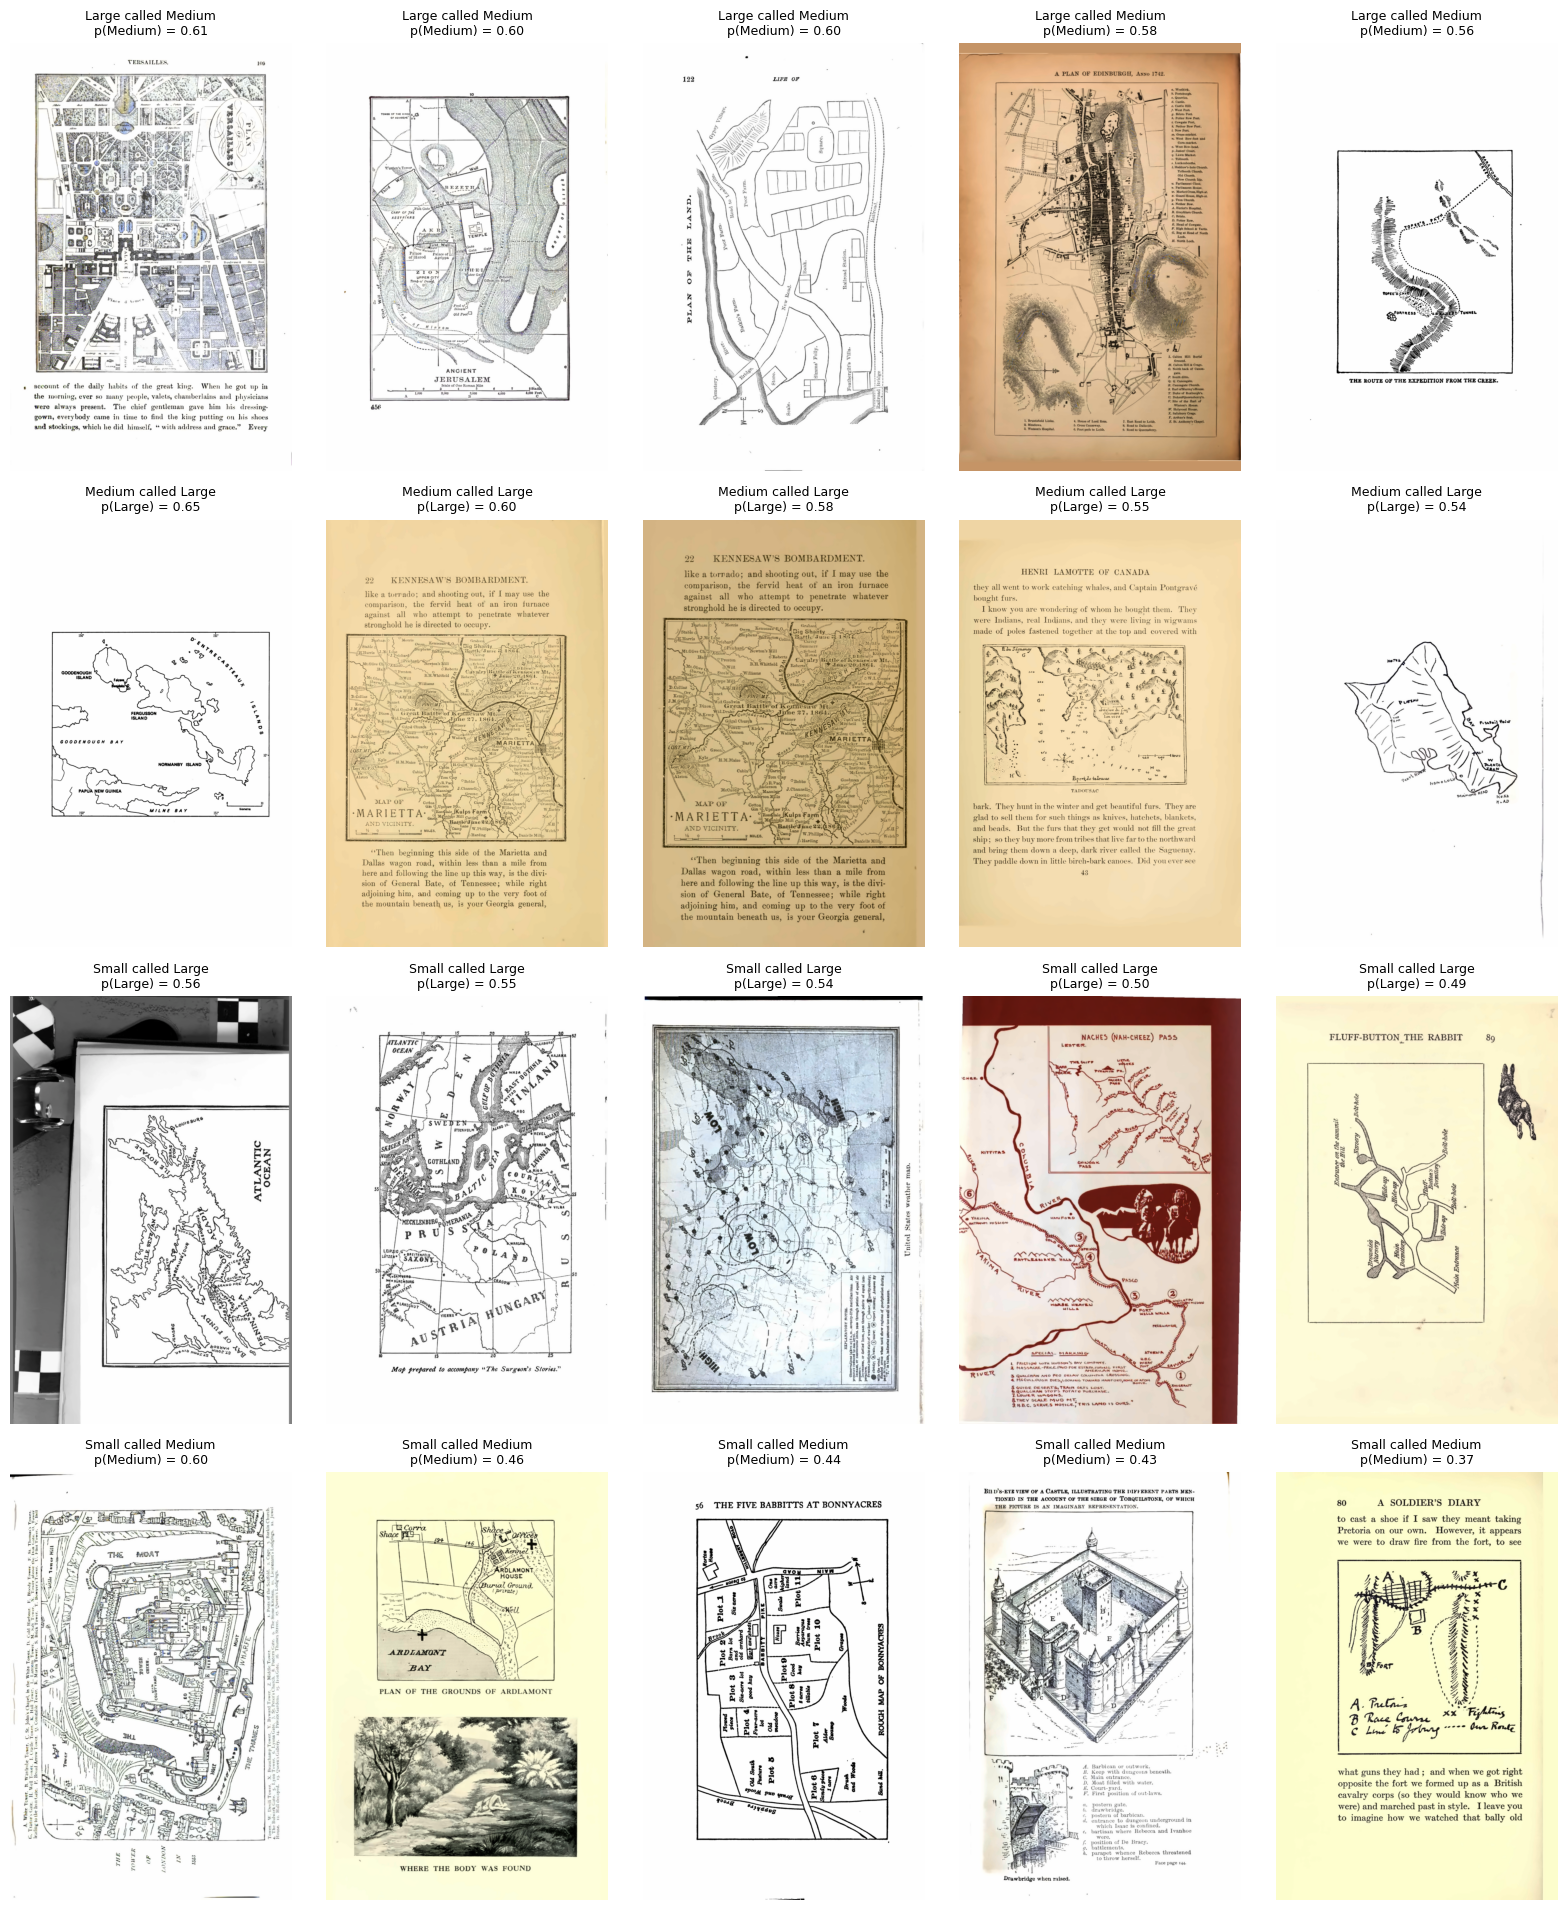

By label_conflict:


,test maps,share correct
label_conflict,,
False,280,0.693
True,11,0.364


By fictionality:


,test maps,share correct
fictionality,,
fictional,101,0.535
real,190,0.758


In [24]:
test_proba = final_model.predict_proba(X["test"])
mistakes = [(2, 1), (1, 2), (0, 2), (0, 1)]   # (true, predicted)
fig, axes = plt.subplots(len(mistakes), N_GALLERY, figsize=(3.2 * N_GALLERY, 4.8 * len(mistakes)))
for row, (tc, pc) in enumerate(mistakes):
    found = np.where((y["test"] == tc) & (test_pred == pc))[0]
    found = found[np.argsort(-test_proba[found, pc])][:N_GALLERY]
    print(f"{CLASS_NAMES[tc]} called {CLASS_NAMES[pc]}: {((y['test'] == tc) & (test_pred == pc)).sum()} test maps")
    for col in range(N_GALLERY):
        ax = axes[row, col]; ax.axis("off")
        if col < len(found):
            i = found[col]
            with Image.open(PROC / splits["test"]["path"][i]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{CLASS_NAMES[tc]} called {CLASS_NAMES[pc]}\np({CLASS_NAMES[pc]}) = {test_proba[i, pc]:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

test_rows = splits["test"].assign(correct=(test_pred == y["test"]))
for column in ["label_conflict", "fictionality"]:
    if column in test_rows.columns:
        print(f"By {column}:")
        display(test_rows.groupby(column)["correct"].agg(["count", "mean"])
                .rename(columns={"count": "test maps", "mean": "share correct"}).round(3))

### 13. Correct for class mix.
Similar to Bayes-offset in the resnet notebook

In [25]:
real_mix = np.bincount(y_train_maps, minlength=3) / len(y_train_maps)
train_mix = np.full(3, 1 / 3) if FINAL_WEIGHTING == "balanced" else np.bincount(y["train"], minlength=3) / len(y["train"])
prior_offset = np.log(real_mix / train_mix); prior_offset -= prior_offset[2]

log_proba = {s: np.log(np.clip(final_model.predict_proba(X[s]), 1e-12, None)) for s in ["val", "test"]}
def predict_with(offset, split):
    return np.argmax(log_proba[split] + np.asarray(offset), axis=1)
assert np.array_equal(predict_with(np.zeros(3), "test"), test_pred)

grid_f1 = np.array([[macro_f1_fast(y["val"], predict_with([s, m, 0.0], "val")) for m in OFFSET_GRID] for s in OFFSET_GRID])
bi, bj = np.unravel_index(np.argmax(grid_f1), grid_f1.shape)
best_val_pred = predict_with([OFFSET_GRID[bi], OFFSET_GRID[bj], 0.0], "val")
best_se = np.std([macro_f1_fast(y["val"][r], best_val_pred[r]) for r in val_resamples])
sg, mg = np.meshgrid(OFFSET_GRID, OFFSET_GRID, indexing="ij")
tied_grid = grid_f1 >= grid_f1[bi, bj] - best_se
pi, pj = np.unravel_index(np.argmin(np.where(tied_grid, np.hypot(sg, mg), np.inf)), grid_f1.shape)
tuned_offset = np.array([OFFSET_GRID[pi], OFFSET_GRID[pj], 0.0])
print(f"Prior-correction offsets (S, M): {prior_offset[0]:+.2f}, {prior_offset[1]:+.2f}")
print(f"Best on val: {OFFSET_GRID[bi]:+.2f}, {OFFSET_GRID[bj]:+.2f} (val macro-F1 {grid_f1[bi, bj]:.3f}, SE {best_se:.3f})")
print(f"Tuned (one-SE): {tuned_offset[0]:+.2f}, {tuned_offset[1]:+.2f} (val macro-F1 {grid_f1[pi, pj]:.3f})")

versions = {"original": np.zeros(3), "prior correction": prior_offset, "tuned offsets (one-SE)": tuned_offset}
vrows, vpreds = [], {}
rng = np.random.default_rng(SEED)
draws = [rng.integers(0, n_test, n_test) for _ in range(N_BOOTSTRAP)]
for name, off in versions.items():
    vp_val, vp_test = predict_with(off, "val"), predict_with(off, "test")
    vpreds[name] = vp_test
    gain = [macro_f1_fast(y["test"][r], vp_test[r]) - macro_f1_fast(y["test"][r], test_pred[r]) for r in draws]
    vrows.append({"version": name, "Small off": off[0], "Medium off": off[1],
                  "val macro-F1": macro_f1_fast(y["val"], vp_val), "test macro-F1": macro_f1_fast(y["test"], vp_test),
                  "test macro MAE": macro_mae(y["test"], vp_test), "test accuracy": accuracy_score(y["test"], vp_test),
                  "test predicted (S,M,L)": str(tuple(int(n) for n in np.bincount(vp_test, minlength=3))),
                  "gain vs original (paired 95%)": "-" if name == "original" else
                      f"{np.mean(gain):+.3f} ({np.percentile(gain, 2.5):+.3f} to {np.percentile(gain, 97.5):+.3f})"})
display(pd.DataFrame(vrows).set_index("version").round(3))

Prior-correction offsets (S, M): -1.39, -1.38
Best on val: +0.00, +0.00 (val macro-F1 0.557, SE 0.036)
Tuned (one-SE): +0.00, +0.00 (val macro-F1 0.557)


,Small off,Medium off,val macro-F1,test macro-F1,test macro MAE,test accuracy,"test predicted (S,M,L)",gain vs original (paired 95%)
version,,,,,,,,
original,0.000,0.000,0.557,0.579,0.486,0.680,"(25, 91, 175)",-
prior correction,-1.386,-1.378,0.281,0.295,0.980,0.735,"(0, 2, 289)",-0.281 (-0.360 to -0.200)
tuned offsets (one-SE),0.000,0.000,0.557,0.579,0.486,0.680,"(25, 91, 175)",+0.000 (+0.000 to +0.000)


### 14. Efficiency

In [26]:
eff = pd.DataFrame([
    {"model": "simple features (combo)", "inference ms/image (CPU, 1 thread)": SIMPLE_MS_PER_IMAGE, "test macro-F1": simple_pred is not None and macro_f1_fast(y["test"], simple_pred)},
    {"model": "ResNet-50 + PCA 64 + LR", "inference ms/image (CPU, 1 thread)": RESNET_MS_PER_IMAGE, "test macro-F1": resnet_pred is not None and macro_f1_fast(y["test"], resnet_pred)},
    {"model": f"DINOv2 + {pca_label(FINAL_DIMS)} + LR",
     "inference ms/image (CPU, 1 thread)": embed_ms_per_image + 1000 * predict_seconds / n_test, "test macro-F1": test_scores["macro_f1"]},
])
print(f"DINOv2 fit (scale + PCA + LR): {fit_seconds:.2f} s; embedding all {sum(len(splits[s]) for s in splits)} images on "
      f"{extract_device['train']}: {sum(extract_seconds.values()):.0f} s")
eff.round(3)

DINOv2 fit (scale + PCA + LR): 0.07 s; embedding all 3654 images on mps: 325 s


,model,"inference ms/image (CPU, 1 thread)",test macro-F1
0,simple features (combo),29.600,0.331
1,ResNet-50 + PCA 64 + LR,142.000,0.511
2,DINOv2 + PCA 32 + LR,203.343,0.579


### Save results and pca features

In [27]:
# Metrics + predictions
(ci_f1, ci_mae) = bootstrap_ci(test_pred)
results = {
    "run_date": time.strftime("%Y-%m-%d"), "model": MODEL_NAME, "pooling": POOLING, "embed_size": list(EMBED_SIZE),
    "pca_dims": FINAL_DIMS, "class_weight": FINAL_WEIGHTING, "C": FINAL_C, "selection_rule": SELECTION_RULE,
    "val_macro_f1": float(val_scores["macro_f1"]), "test_macro_f1": float(test_scores["macro_f1"]),
    "test_macro_f1_95ci": [float(v) for v in ci_f1], "test_macro_mae": float(test_scores["macro_mae"]),
    "test_macro_mae_95ci": [float(v) for v in ci_mae], "test_accuracy": float(test_scores["accuracy"]),
    "inference_ms_per_image": float(embed_ms_per_image + 1000 * predict_seconds / n_test),
}
(RESULTS_DIR / "5-dinov2.json").write_text(json.dumps(results, indent=2))
pd.DataFrame({"path": splits["test"]["path"], "label": y["test"], "pred": test_pred}).to_csv(
    RESULTS_DIR / "5-dinov2_test_predictions.csv", index=False)

# PCA features for both models
def save_pca_features(tag, pipeline, Xm):
    transform = pipeline[:-1]            # scaler + PCA, without the logistic regression
    for s in splits:
        Z = transform.transform(Xm[s]).astype(np.float32)
        np.savez(FEATURE_DIR / f"{tag}_{s}.npz", X=Z, paths=np.array(splits[s]["path"]), y=y[s])
    print(f"saved {tag}_<split>.npz  ({Z.shape[1]} columns)")

save_pca_features(f"dinov2_pca{FINAL_DIMS}" if FINAL_DIMS < EMBED_DIM else "dinov2_scaled", final_model, X)
if resnet_model is not None:
    save_pca_features(f"resnet50_pca{RESNET_PCA}", resnet_model, X_res)
print("Saved results to", RESULTS_DIR)

saved dinov2_pca32_<split>.npz  (32 columns)
saved resnet50_pca64_<split>.npz  (64 columns)
Saved results to /Users/hsinyehtsai/281/281project/data/results
